# Overview of mergeplg

mergeplg is a tool for processing rainfall data. It is used to **interpolate** rainfall measurements from commercial microwave links (CMLs) and rain gauges, and **merge** them with gridded radar data into a single dataset.

The tool works on two levels:
1. Low-level functions handle core interpolation methods like inverse distance weighting (IDW) and kriging.
2. High-level functions make workflows easier and faster by reusing calculations wherever possible, such as across time steps in kriging or for extracting radar data along CML paths. They also define some standard parameters that we have found useful. 

All functions and classes are documented in the [API reference](../api.md).

mergeplg also includes an implementation of the RADOLAN method, the radar adjustment approach used by the German Weather Service (DWD). It is available as the high-level class `merge.MergeRADOLAN`. 

In this overview, we will work with both the high-level functions and the RADOLAN method.

mergeplg works with data formatted according to the OpenSense data format convention:  
https://github.com/OpenSenseAction/OS_data_format_conventions  

We will use data from the OpenRainER dataset. For details on how this data was processed, check the notebook:  
`./data/OpenRainER_cmlProcessing.ipynb`

We will also use the poligrain package for plotting and calculating metrics:  
https://poligrain.readthedocs.io/en/latest/

A preprint exploring the performance of the different merging methods is available from:  
https://doi.org/10.5194/egusphere-2025-6371

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import poligrain as plg
import xarray as xr
from sklearn.model_selection import train_test_split

from mergeplg import interpolate, merge

In [2]:
# Load data
ds_gauges = xr.open_dataset("./data/openrainer_AWS.nc")
ds_cmls = xr.open_dataset("./data/openrainer_CML.nc")
ds_rad = xr.open_dataset("./data/openrainer_RAD.nc")

In [3]:
# Average both CML sublinks
ds_cmls = ds_cmls.reduce(np.nanmean, dim="sublink_id")

# Rename metadata
ds_gauges = ds_gauges.rename({"longitude": "lon", "latitude": "lat"})
ds_rad = ds_rad.rename({"lon": "x", "lat": "y"})
ds_rad = ds_rad.rename({"rainfall_amount": "rainfall_radar"})  # more explicit name
# needed to avoid pandas warning in RADOLAN code that uses .loc[]
ds_rad["rainfall_radar"] = ds_rad.rainfall_radar.astype("float64")
ys = [
    ds_rad.y.values,
] * len(ds_rad.x.values)
xs = [
    ds_rad.x.values,
] * len(ds_rad.y.values)
ds_rad["lat"] = (("y", "x"), np.array(ys).transpose())
ds_rad["lon"] = (("y", "x"), np.array(xs))
ds_rad = ds_rad.set_coords(["lon", "lat"])

In [4]:
# Transform rainfall rates to mm/h (from 15 min accumulated rainfall)
ds_gauges["rainfall_amount"] = ds_gauges.rainfall_amount * 60 / 15
ds_cmls["R"] = ds_cmls.R * 60 / 15
ds_rad["rainfall_radar"] = ds_rad.rainfall_radar * 60 / 15

# Factor to convert mm/h back to mm per 15 min time step, used when
# plotting rainfall sums
mmh_to_mm = 15 / 60

## Project data

In [5]:
# UTM32N: https://epsg.io/32632
ref_str = "EPSG:32632"

# Project gauge data
ds_gauges.coords["x"], ds_gauges.coords["y"] = plg.spatial.project_point_coordinates(
    ds_gauges.lon, ds_gauges.lat, ref_str
)

# For CML
(
    ds_cmls.coords["site_0_x"],
    ds_cmls.coords["site_0_y"],
) = plg.spatial.project_point_coordinates(
    ds_cmls.site_0_lon, ds_cmls.site_0_lat, ref_str
)
(
    ds_cmls.coords["site_1_x"],
    ds_cmls.coords["site_1_y"],
) = plg.spatial.project_point_coordinates(
    ds_cmls.site_1_lon, ds_cmls.site_1_lat, ref_str
)

# Midpoint
ds_cmls.coords["x"] = (ds_cmls.site_0_x + ds_cmls.site_1_x) / 2
ds_cmls.coords["y"] = (ds_cmls.site_0_y + ds_cmls.site_1_y) / 2

# Projected radar coords
ds_rad.coords["x_grid"], ds_rad.coords["y_grid"] = (
    plg.spatial.project_point_coordinates(ds_rad.lon, ds_rad.lat, ref_str)
)

## Create test dataset

In [6]:
# Separate rain gauges for testing
ds_gauges_i, ds_gauges_test_i = train_test_split(
    np.arange(ds_gauges.id.size), test_size=0.33, random_state=42
)
ds_gauges_test = ds_gauges.isel(id=ds_gauges_test_i)
ds_gauges = ds_gauges.isel(id=ds_gauges_i)  # overwrite old dataset

## Interpolate ground observations

### Interpolate when no radar grid is available
Mergeplg requires a grid to be supplied. If no such grid is available, for instance if you simply want to perform interpolation, a grid must be created. 

In [7]:
# Set size of gridcells
gridsize = 2000  # meters

# Create grid in meter using rain gauges
xmin = float(ds_gauges.x.min().astype(int))
xmax = float(ds_gauges.x.max().astype(int))
ymin = float(ds_gauges.y.min().astype(int))
ymax = float(ds_gauges.y.max().astype(int))
x_coords = np.arange(xmin, xmax + gridsize, gridsize)
y_coords = np.arange(ymin, ymax + gridsize, gridsize)
x_grid, y_grid = np.meshgrid(x_coords, y_coords)

# Create empty xarray.DataArray defining the  grid following the OpenSense
# data format, note that the dimension order must be ('time', 'y', 'x').
da_grid = xr.DataArray(
    dims=["time", "y", "x"],
    coords={
        "x": x_coords,
        "y": y_coords,
        "x_grid": (["y", "x"], x_grid),
        "y_grid": (["y", "x"], y_grid),
        "time": ds_gauges.time,
    },
)

In [8]:
# Perform interpolation using Ordinary Kriging. Mergeplg works by first
# calculating interpolation weights for all observations
interpolator = interpolate.InterpolateOrdinaryKriging(
    ds_grid=da_grid,
    ds_gauges=ds_gauges,  # Specify that we use rain gauges
    variogram_parameters={"sill": 1, "range": 30000, "nugget": 0.3},
    variogram_model="spherical",
    nnear=8,  # Number of neighbors used for interpolation
    max_distance=20000,  # Max distance to perform interpolation
)

# The interpolation weights are reused for each time step
rainfall = []
for time in ds_gauges.time.data:
    rainfall.append(
        interpolator(
            da_gauges=ds_gauges.sel(time=time).rainfall_amount,
        ).rainfall
    )

# Combine all time steps
da_rainfall_kriging = xr.concat(rainfall, dim="time")

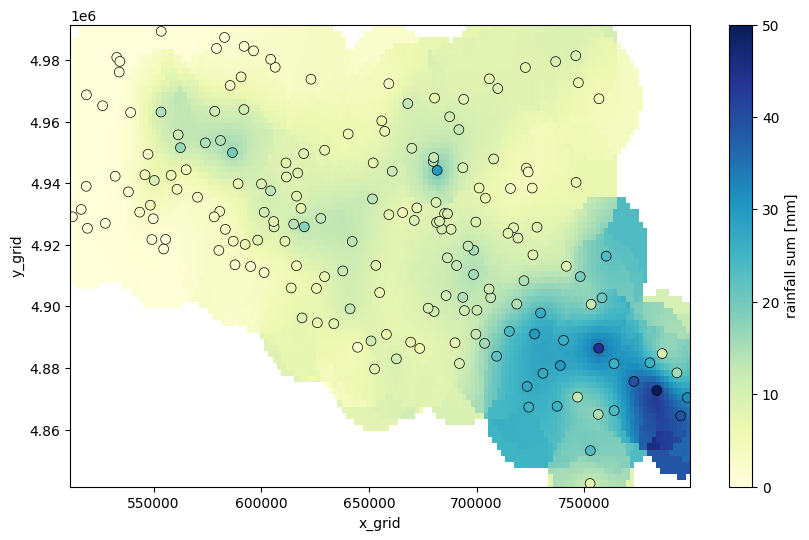

In [9]:
# Plot data using poligrain
fig, ax = plt.subplots(figsize=(10, 6))
plg.plot_map.plot_plg(
    da_grid=da_rainfall_kriging.sum(dim="time", skipna=False) * mmh_to_mm,
    da_gauges=ds_gauges.rainfall_amount.sum(dim="time") * mmh_to_mm,
    use_lon_lat=False,
    vmin=0,
    vmax=50,
    cmap="YlGnBu",
    marker_size=50,
    ax=ax,
    colorbar_label="rainfall sum [mm]",
);

### Interpolate when radar grid is available
Often, a radar grid is available, we can then perform interpolation like this

In [10]:
# Interpolate using IDW
interpolator = interpolate.InterpolateIDW(
    ds_grid=ds_rad.rainfall_radar,  # Dimension order (time, y, x)
    ds_cmls=ds_cmls,  # We can add CMLs to the interpolator
    ds_gauges=ds_gauges,  # And gauges
    p=2,  # IDW interpolator parameter
    nnear=8,
    max_distance=20000,  # Max distance to perform interpolation
)

rainfall = []
for time in ds_cmls.time.data:
    rainfall.append(
        interpolator(
            da_cmls=ds_cmls.sel(time=time).R,
            da_gauges=ds_gauges.sel(time=time).rainfall_amount,
        ).rainfall
    )

# We can then store the interpolated field in the radar dataset
ds_rad["rainfall_interpolateIDW"] = xr.concat(rainfall, dim="time")

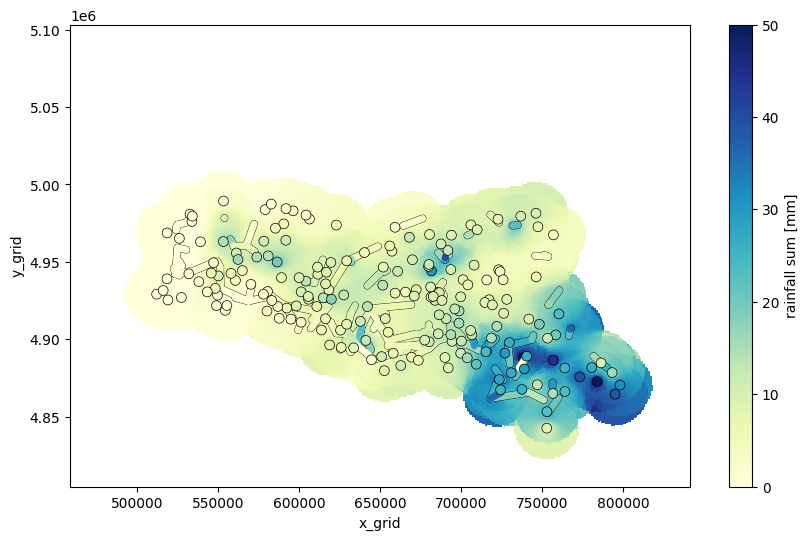

In [11]:
# Plot data using poligrain
fig, ax = plt.subplots(figsize=(10, 6))
plg.plot_map.plot_plg(
    da_grid=ds_rad.rainfall_interpolateIDW.sum(dim="time", skipna=False) * mmh_to_mm,
    da_gauges=ds_gauges.rainfall_amount.sum(dim="time") * mmh_to_mm,
    da_cmls=ds_cmls.R.sum(dim="time") * mmh_to_mm,
    use_lon_lat=False,
    vmin=0,
    vmax=50,
    cmap="YlGnBu",
    marker_size=50,
    ax=ax,
    colorbar_label="rainfall sum [mm]",
);

### Interpolate with uncertain data
Kriging methods allow for assigning uncertainty to individual data - Kriging with Uncertain Data (KUD). In the following we show how to apply this method using mergeplg by passing the estimated error variance of each observation via `da_gauges_sigma`. Note that, despite its name, this argument expects a variance and not a standard deviation. Note that the variogram nugget is ignored when passing sigma to the interpolator. 

In [12]:
# Uncertainty model, this assigns more uncertainty to higher rainfall observations
ds_gauges["variance_rainfall_amount"] = 1 * (
    1 - np.exp(-ds_gauges.rainfall_amount / 20)
)

In [13]:
# Perform interpolation using Ordinary Kriging. Mergeplg works by first
# calculating interpolation weights for all observations
interpolator = interpolate.InterpolateOrdinaryKriging(
    ds_grid=da_grid,
    ds_gauges=ds_gauges,  # Specify that we use rain gauges
    variogram_parameters={"sill": 1, "range": 30000, "nugget": 0.3},
    variogram_model="spherical",
    nnear=12,  # Number of neighbors used for interpolation
    max_distance=30000,  # max distance to perform interpolation
)

# The interpolation weights are reused for each time step. Kriging returns
# both the interpolated rainfall and the kriging variance, so here we keep
# the full xarray.Dataset
interpolated = []
for time in ds_gauges.time.data:
    interpolated.append(
        interpolator(
            da_gauges=ds_gauges.sel(time=time).rainfall_amount,
            da_gauges_sigma=ds_gauges.sel(time=time).variance_rainfall_amount,
        )
    )

ds_interpolated = xr.concat(interpolated, dim="time")

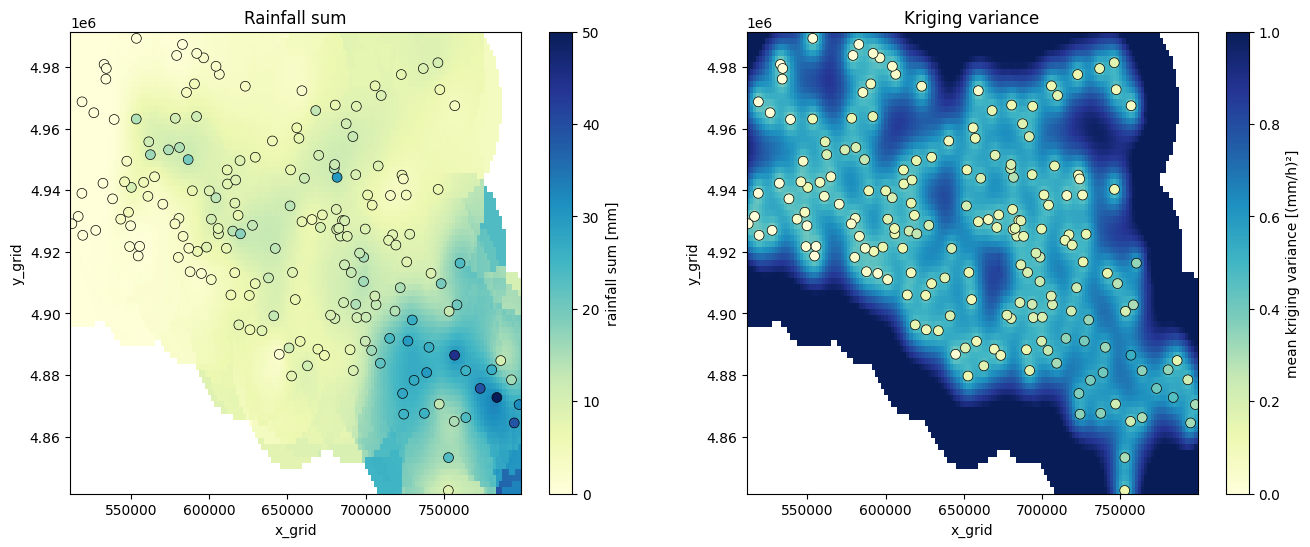

In [14]:
# Plot rainfall sum and the mean kriging variance using poligrain
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plg.plot_map.plot_plg(
    da_grid=ds_interpolated.rainfall.sum(dim="time", skipna=False) * mmh_to_mm,
    da_gauges=ds_gauges.rainfall_amount.sum(dim="time") * mmh_to_mm,
    use_lon_lat=False,
    vmin=0,
    vmax=50,
    cmap="YlGnBu",
    marker_size=50,
    ax=ax[0],
    colorbar_label="rainfall sum [mm]",
)
ax[0].set_title("Rainfall sum")

# The kriging variance is low close to observations with low uncertainty
# and increases with distance and with the uncertainty assigned to the
# observations. The gauges show their mean assigned error variance.
plg.plot_map.plot_plg(
    da_grid=ds_interpolated.variance.mean(dim="time"),
    da_gauges=ds_gauges.variance_rainfall_amount.mean(dim="time"),
    use_lon_lat=False,
    vmin=0,
    vmax=1,
    cmap="YlGnBu",
    marker_size=50,
    ax=ax[1],
    colorbar_label="mean kriging variance [(mm/h)²]",
)
ax[1].set_title("Kriging variance");

## Merge ground observations with radar data

### IDW additive

In [15]:
merger = merge.MergeDifferenceIDW(
    ds_rad=ds_rad.rainfall_radar,  # Dimension order (time, y, x)
    ds_cmls=ds_cmls,
    # ds_gauges=ds_gauges, # uncomment to include rain gauges
    p=2,  # IDW interpolator parameter
    nnear=8,  # Number of nearby observations to use
    max_distance=60000,  # Largest distance allowed for including an observation
    method="additive",  # Additive/Multiplicative merging
    radar_threshold=0.01,  # Radar values below this threshold are ignored when merging
    fill_radar=False,  # If True, fills cells beyond max_distance with unadjusted radar
    range_checks={"diff_check": 10},  # Removes large radar-ground differences
)

rainfall = []
for time in ds_cmls.time.data:
    rainfall.append(
        merger(
            da_rad=ds_rad.sel(time=time).rainfall_radar,
            da_cmls=ds_cmls.R.sel(time=time),
            # uncomment to include rain gauges
            # da_gauges=ds_gauges.sel(time=time).rainfall_amount,
        ).rainfall
    )

# Store merged data together with radar data
ds_rad["rainfall_additiveIDW"] = xr.concat(rainfall, dim="time")

### Ordinary Kriging additive

In [16]:
merger = merge.MergeDifferenceOrdinaryKriging(
    ds_rad=ds_rad.rainfall_radar,  # Dimension order (time, y, x)
    ds_cmls=ds_cmls,
    # ds_gauges=ds_gauges, # uncomment to include rain gauges
    variogram_model="spherical",
    variogram_parameters={"sill": 1, "range": 30000, "nugget": 0.3},
    method="additive",  # Additive/Multiplicative merging
    nnear=8,  # Number of nearby observations to use
    max_distance=60000,  # Largest distance allowed for including an observation
    full_line=True,  # Use the full line geometry in block kriging
    radar_threshold=0.01,  # Radar values below this threshold are ignored when merging
    fill_radar=False,  # If True, fills cells beyond max_distance with unadjusted radar
    range_checks={"diff_check": 10},  # Removes large radar-ground differences
)

rainfall = []
for time in ds_cmls.time.data:
    rainfall.append(
        merger(
            da_rad=ds_rad.sel(time=time).rainfall_radar,
            da_cmls=ds_cmls.R.sel(time=time),
            # uncomment to include rain gauges
            # da_gauges=ds_gauges.sel(time=time).rainfall_amount,
        ).rainfall
    )

# Store merged data together with radar data
ds_rad["rainfall_additiveBKline"] = xr.concat(rainfall, dim="time")

### Ordinary Kriging additive with CMLs and rain gauges
All merging methods can use rain gauges in addition to CMLs. Here we repeat the ordinary kriging merging above and add the training rain gauges. The test rain gauges are not used, so they can still be used for validation.

In [17]:
merger = merge.MergeDifferenceOrdinaryKriging(
    ds_rad=ds_rad.rainfall_radar,  # Dimension order (time, y, x)
    ds_cmls=ds_cmls,
    ds_gauges=ds_gauges,  # Training rain gauges, test gauges are kept apart
    variogram_model="spherical",
    variogram_parameters={"sill": 1, "range": 30000, "nugget": 0.3},
    method="additive",  # Additive/Multiplicative merging
    nnear=8,  # Number of nearby observations to use
    max_distance=60000,  # Largest distance allowed for including an observation
    full_line=True,  # Use the full line geometry in block kriging
    radar_threshold=0.01,  # Radar values below this threshold are ignored when merging
    fill_radar=False,  # If True, fills cells beyond max_distance with unadjusted radar
    range_checks={"diff_check": 10},  # Removes large radar-ground differences
)

rainfall = []
for time in ds_cmls.time.data:
    rainfall.append(
        merger(
            da_rad=ds_rad.sel(time=time).rainfall_radar,
            da_cmls=ds_cmls.R.sel(time=time),
            da_gauges=ds_gauges.sel(time=time).rainfall_amount,
        ).rainfall
    )

# Store merged data together with radar data
ds_rad["rainfall_additiveBKlineGauges"] = xr.concat(rainfall, dim="time")

### Kriging with external drift

In [18]:
merger = merge.MergeKrigingExternalDrift(
    ds_rad=ds_rad.rainfall_radar,  # Dimension order (time, y, x)
    ds_cmls=ds_cmls,
    # ds_gauges=ds_gauges, # uncomment to include rain gauges
    variogram_model="spherical",
    variogram_parameters={"sill": 1, "range": 30000, "nugget": 0.3},
    nnear=70,  # KED tends to work better with larger neighborhood
    max_distance=60000,  # Largest distance allowed for including an observation
    full_line=True,
    radar_threshold=0.01,  # Radar values below this threshold are ignored when merging
    fill_radar=False,  # If True, fills cells beyond max_distance with unadjusted radar
    range_checks={"diff_check": 10},  # Removes large radar-ground differences
)

rainfall = []
for time in ds_cmls.time.data:
    rainfall.append(
        merger(
            ds_rad.sel(time=time).rainfall_radar,
            da_cmls=ds_cmls.sel(time=time).R,
            # uncomment to include rain gauges
            # da_gauges=ds_gauges.sel(time=time).rainfall_amount,
        ).rainfall
    )

# Store merged data together with radar data
ds_rad["rainfall_KED"] = xr.concat(rainfall, dim="time")

### RADOLAN
The RADOLAN method, used by the German Weather Service (DWD), is applied in the same way as the other merging methods.

In [19]:
# The RADOLAN code finds the stations with radar coverage by checking the
# min and max range of the x and y coordinates of the radar grid. These must
# thus be in the same projection as the CMLs. We overwrite x and y with the
# projected coordinates. Note that x_grid and y_grid are 2D and not
# equidistant, but for this dataset this does not make a difference because
# the radar coverage is far larger than the area covered by the CMLs.
ds_rad.coords["x"] = ds_rad.x_grid.isel(y=0).values
ds_rad.coords["y"] = ds_rad.y_grid.isel(x=0).values

merger = merge.MergeRADOLAN(
    ds_rad=ds_rad.rainfall_radar,  # Dimension order (time, y, x)
    ds_cmls=ds_cmls,
    # ds_gauges=ds_gauges, # uncomment to include rain gauges
    max_distance=60000,  # Largest distance allowed for including an observation
    grid_location_radar="lower_left",  # Position of radar value in grid cell
)

rainfall = []
for time in ds_cmls.time.data:
    rainfall.append(
        merger(
            da_rad=ds_rad.sel(time=time).rainfall_radar,
            da_cmls=ds_cmls.R.sel(time=time),
            # uncomment to include rain gauges
            # da_gauges=ds_gauges.sel(time=time).rainfall_amount,
            start_index_in_relevant_stations=0,  # Makes result reproducible
        ).rainfall
    )

# Store merged data together with radar data
ds_rad["rainfall_RADOLAN"] = xr.concat(rainfall, dim="time")

## Plot merged fields 

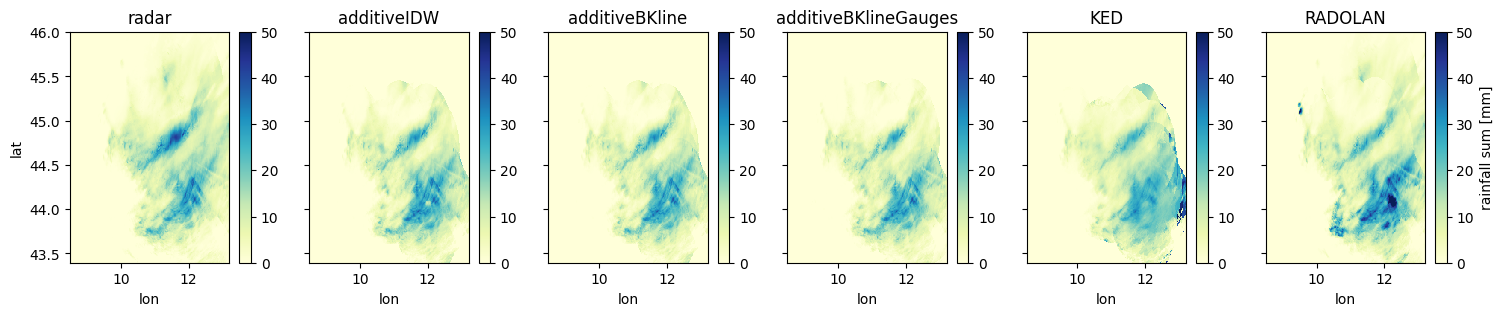

In [20]:
# Specify rainfall fields to plot
rainfall_fields = [
    "rainfall_radar",
    "rainfall_additiveIDW",
    "rainfall_additiveBKline",
    "rainfall_additiveBKlineGauges",
    "rainfall_KED",
    "rainfall_RADOLAN",
]

# Plot data using poligrain
fig, ax = plt.subplots(
    1,
    len(rainfall_fields),
    figsize=(len(rainfall_fields) * 3, 3),
    sharex=True,
    sharey=True,
)
for i, rainfall_field in enumerate(rainfall_fields):
    plg.plot_map.plot_plg(
        # nan are treated as zero in the sum
        da_grid=ds_rad[rainfall_field].sum(dim="time", skipna=True) * mmh_to_mm,
        use_lon_lat=True,
        vmin=0,
        vmax=50,
        cmap="YlGnBu",
        ax=ax[i],
        add_colorbar=True,
        colorbar_label="rainfall sum [mm]" if i == len(rainfall_fields) - 1 else "",
    )
    ax[i].set_title(rainfall_field.split("_")[1])
    if i != 0:
        ax[i].set_ylabel("")

## Compare merged fields with rain gauges

In [21]:
# Get fields at validation rain gauges
get_grid_at_points = plg.spatial.GridAtPoints(
    da_gridded_data=ds_rad.rainfall_radar,  # Coordinates for all rainfall fields
    da_point_data=ds_gauges_test,  # Coordinates for test rain gauges
    nnear=1,
    stat="best",
)

# Sample rainfall fields
for rainfall_field in rainfall_fields:
    ds_gauges_test[rainfall_field] = get_grid_at_points(
        da_gridded_data=ds_rad[rainfall_field],
        da_point_data=ds_gauges_test.rainfall_amount,
    )

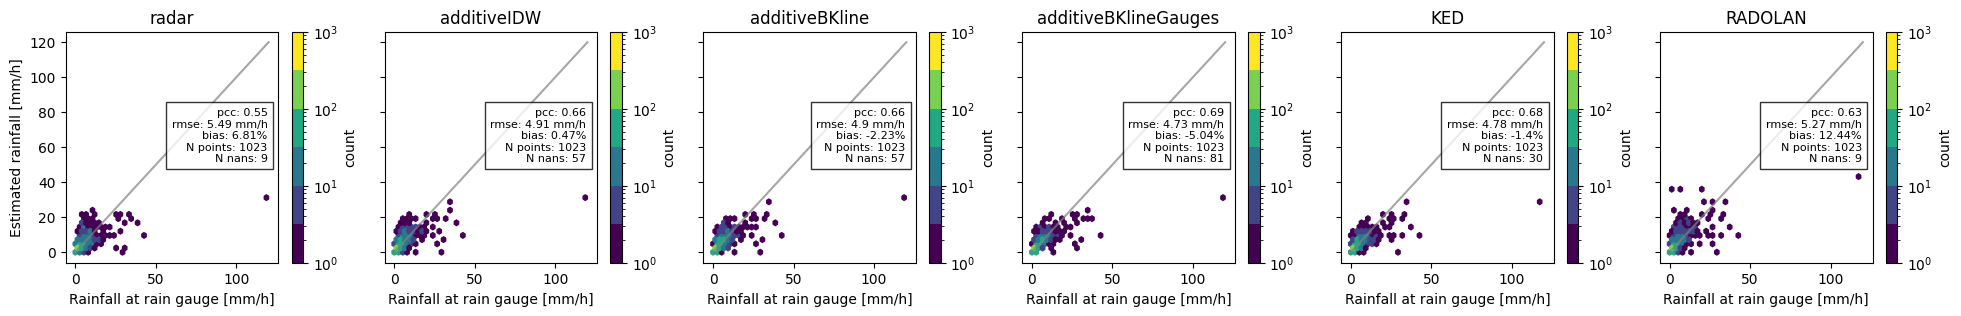

In [22]:
threshold = 0.1  # Values below this are ignored

# Rain gauges from test dataset considered ground truth
ground_truth = ds_gauges_test.rainfall_amount.to_numpy().flatten()

# Plot metrics and scatterplots
fig, ax = plt.subplots(
    1,
    len(rainfall_fields),
    figsize=(len(rainfall_fields) * 4, 3),
    sharex=True,
    sharey=True,
)
for i, rainfall_field in enumerate(rainfall_fields):
    # Get predictions at test gauges
    predicted = ds_gauges_test[rainfall_field].to_numpy().flatten()

    rainfall_metrics = plg.validation.calculate_rainfall_metrics(
        reference=ground_truth,
        estimate=predicted,
        ref_thresh=threshold,
        est_thresh=threshold,
    )

    # plotting the scatter density plots
    hx = plg.validation.plot_hexbin(
        ground_truth,
        predicted,
        ref_thresh=threshold,
        est_thresh=threshold,
        ax=ax[i],
    )
    ax[i].set_title(rainfall_field.split("_")[1])
    if i == 0:
        ax[i].set_ylabel("Estimated rainfall [mm/h]")
    else:
        ax[i].set_ylabel("")

    ax[i].set_xlabel("Rainfall at rain gauge [mm/h]")

    # adding metrics to the plot for subplot 0
    plotted_metrics = (
        f"pcc: {np.round(rainfall_metrics['pearson_correlation_coefficient'], 2)}\n"
        f"rmse: {np.round(rainfall_metrics['root_mean_square_error'], 2)} mm/h\n"
        f"bias: {np.round(rainfall_metrics['percent_bias'], 2)}%\n"
        f"N points: {rainfall_metrics['N_all']}\n"
        f"N nans: {rainfall_metrics['N_nan']}"
    )

    ax[i].text(
        0.95,
        0.55,
        plotted_metrics,
        fontsize=8,
        transform=ax[i].transAxes,
        verticalalignment="center",
        horizontalalignment="right",
        bbox={"facecolor": "white", "alpha": 0.8},
    )